# Project 2
## Goals
Use scheduled flight information to predict:

1. Binary classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more

2. Multiclass classification:
- 0: flight delays under 15 minutes
- 1: flight delays of 15 minutes or more and under 60 minutes
- 2: flight delays of 60 minutes or more

In [3]:
from pathlib import Path
from time import perf_counter
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

In [8]:
SEED = 10
MAX_SAMPLES = 20000
CV_FOLDS = 5
OUTPUT_DIR = Path("project2_output")
OUTPUT_DIR.mkdir(exist_ok=True)

In [13]:
categorical_features = [
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
]

numeric_features = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "SCHEDULED_DEPARTURE_HOUR",
    "SCHEDULED_DEPARTURE_MINUTE",
    "SCHEDULED_ARRIVAL_HOUR",
    "SCHEDULED_ARRIVAL_MINUTE",
    "SCHEDULED_TIME",
    "DISTANCE",
]

source_columns = [
    "MONTH",
    "DAY",
    "DAY_OF_WEEK",
    "AIRLINE",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "SCHEDULED_DEPARTURE",
    "SCHEDULED_ARRIVAL",
    "SCHEDULED_TIME",
    "DISTANCE",
    "ARRIVAL_DELAY",
    "CANCELLED",
    "DIVERTED",
]

def process_HHMM_time(data):
    values = pd.to_numeric(data, errors="coerce")
    valid = values.notna() & values.mod(1).eq(0) & ((values.between(0, 2359) & values.mod(100).lt(60)) | values.eq(2400))
    values = values.where(valid).replace(2400, 0)
    return values.floordiv(100), values.mod(100)

processed_path = Path("data/preprocessed_flights.csv")
raw_path = Path("data/flights.csv")

data_path = processed_path if processed_path.exists() else raw_path

if not data_path.exists():
    raise FileNotFoundError(
        "File not found."
    )

df = pd.read_csv(
    data_path,
    usecols=lambda column: column in source_columns,
    dtype={column: "string" for column in categorical_features},
    low_memory=False,
)

loaded_rows = len(df)

for column in set(df.columns) - set(categorical_features):
    df[column] = pd.to_numeric(df[column], errors="coerce")

if "CANCELLED" in df.columns:
    df = df.loc[df["CANCELLED"].eq(0)].copy()

df = df.loc[
    df["DIVERTED"].eq(0)
    & df["ARRIVAL_DELAY"].notna()
    & np.isfinite(df["ARRIVAL_DELAY"])
].copy()

eligible_rows = len(df)

if MAX_SAMPLES is not None and len(df) > MAX_SAMPLES:
    df = df.sample(n=MAX_SAMPLES, random_state=SEED)

df = df.reset_index(drop=True)

# Normalize categorical missing values
for column in categorical_features:
    values = df[column].astype("string").str.strip()
    df[column] = values.replace("", pd.NA).astype(object)
    df.loc[pd.isna(df[column]), column] = np.nan

if len(df) < 200:
    raise ValueError("The project requires at least 200 samples per problem.")

df["SCHEDULED_DEPARTURE_HOUR"], df["SCHEDULED_DEPARTURE_MINUTE"] = process_HHMM_time(df["SCHEDULED_DEPARTURE"])
df["SCHEDULED_ARRIVAL_HOUR"], df["SCHEDULED_ARRIVAL_MINUTE"] = process_HHMM_time(df["SCHEDULED_ARRIVAL"])

print("Source:", data_path)
print(f"Loaded rows: {loaded_rows:,}")
print(f"Eligible rows: {eligible_rows:,}")
print(f"Selected rows: {len(df):,}")

display(df.head())

Source: data/flights.csv
Loaded rows: 5,819,079
Eligible rows: 5,714,008
Selected rows: 20,000


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,SCHEDULED_TIME,DISTANCE,SCHEDULED_ARRIVAL,ARRIVAL_DELAY,DIVERTED,CANCELLED,SCHEDULED_DEPARTURE_HOUR,SCHEDULED_DEPARTURE_MINUTE,SCHEDULED_ARRIVAL_HOUR,SCHEDULED_ARRIVAL_MINUTE
0,12,28,1,WN,DEN,JAX,1825,185.0,1447,2330,58.0,0,0,18,25,23,30
1,3,19,4,MQ,IND,JFK,1245,124.0,665,1449,5.0,0,0,12,45,14,49
2,10,31,6,EV,10397,10685,2109,104.0,533,2153,-8.0,0,0,21,9,21,53
3,8,4,2,UA,SNA,DEN,1542,138.0,846,1900,-10.0,0,0,15,42,19,0
4,3,29,7,UA,DEN,SAN,2207,143.0,853,2330,-12.0,0,0,22,7,23,30


# Predictors:
- Date of flight (Month, day, and day of week)
- scheduled duration
- scheduled distance
- scheduled departure hour and minute
- scheduled arrival hour and minute
- airline
- origin airport
- destination airport

# Excluded predictors:
- Actual departure time
- Actual arrival time
- Departure delay
- Taxi times
- elapsed time
- delay-cause
These variables are removed from the data frame to prevent outcome leakage.

# response variable: 
- Arrival delay

In [15]:
feature_cols = categorical_features + numeric_features
X = df[feature_cols].copy()

X[numeric_features] = X[numeric_features].replace([np.inf, -np.inf], np.nan).astype(float)

targets = {
    "binary": df["ARRIVAL_DELAY"].ge(15).astype(int),
    "multiclass": pd.Series(np.select([
        df["ARRIVAL_DELAY"].lt(15),
        df["ARRIVAL_DELAY"].lt(60),
    ], [0, 1], default=2),
    index=df.index),
}

class_names = {
    "binary": ["on_time", "delayed"],
    "multiclass": ["on_time", "minor_delay", "major_delay"],
}

for classificationtype in targets:
    targets[classificationtype] = targets[classificationtype].rename(f"{classificationtype}_response")

display(X.isna().mean().to_frame("missing_fraction").sort_values("missing_fraction", ascending=False))

,missing_fraction
AIRLINE,0.0
ORIGIN_AIRPORT,0.0
DESTINATION_AIRPORT,0.0
MONTH,0.0
DAY,0.0
DAY_OF_WEEK,0.0
SCHEDULED_DEPARTURE_HOUR,0.0
SCHEDULED_DEPARTURE_MINUTE,0.0
SCHEDULED_ARRIVAL_HOUR,0.0
SCHEDULED_ARRIVAL_MINUTE,0.0


We will use a stratified 90/10 training/testing split on all of our models.

In [23]:

from sklearn.model_selection import train_test_split

splits = {}

for classificationtype, y in targets.items():
    if y.value_counts().min() < 10:
        raise ValueError(f"Not enough samples for {classificationtype} classification.")

    training, validation = train_test_split(
        np.arange(len(X)),
        test_size=0.10,
        stratify=y,
        random_state=SEED,
    )

    X_train = X.iloc[training].copy()
    y_train = y.iloc[training].copy()
    X_validation = X.iloc[validation].copy()
    y_validation = y.iloc[validation].copy()

    if y_train.value_counts().min() < CV_FOLDS:
        raise ValueError(f"Not enough training samples for {classificationtype} classification.")

    splits[classificationtype] = (X_train, y_train, X_validation, y_validation)

    # all data for task
    pd.concat([X, y], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}.csv",
        index=False,
    )

    # training and validation data for task
    pd.concat([X_train, y_train], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_train.csv",
        index=False,
    )

    pd.concat([X_validation, y_validation], axis=1).to_csv(
        OUTPUT_DIR / f"flights_{classificationtype}_validation.csv",
        index=False,
    )

    print(f"{classificationtype}: {len(X_train):,} training samples, {len(X_validation):,} validation samples")


binary: 18,000 training samples, 2,000 validation samples
multiclass: 18,000 training samples, 2,000 validation samples


In [ ]:
# explore data (visualization and stuff like that)

In [21]:

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

model_specs = {
    "decision_tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [3, 5, 10, 15, 20]}
    ),
    "svm": (
        SVC(random_state=SEED),
        {"model__kernel": ["linear", "poly", "rbf"]}
    )
}

models = list(model_specs)
for model in models:
    model_estimator, hyperparameters = model_specs[model]
    print(f"{model}: {model_estimator} with hyperparameters {hyperparameters}")

decision_tree: DecisionTreeClassifier(random_state=10) with hyperparameters {'model__max_depth': [3, 5, 10, 15, 20]}
svm: SVC(random_state=10) with hyperparameters {'model__kernel': ['linear', 'poly', 'rbf']}


In [22]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

def make_pipeline(model_estimator):
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ]
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", clone(model_estimator)),
    ])

    return pipeline

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7910
Validation balanced accuracy: 0.5246
Validation macro F1:          0.5190
Final training runtime:       0.2300 seconds
Prediction runtime:           0.0053 seconds


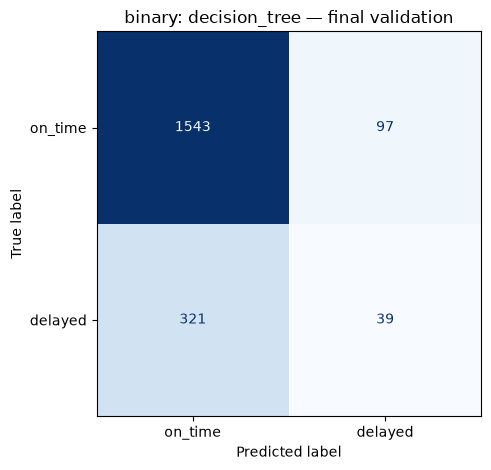

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8180
Validation balanced accuracy: 0.5020
Validation macro F1:          0.4580
Final training runtime:       13.8518 seconds
Prediction runtime:           0.3079 seconds


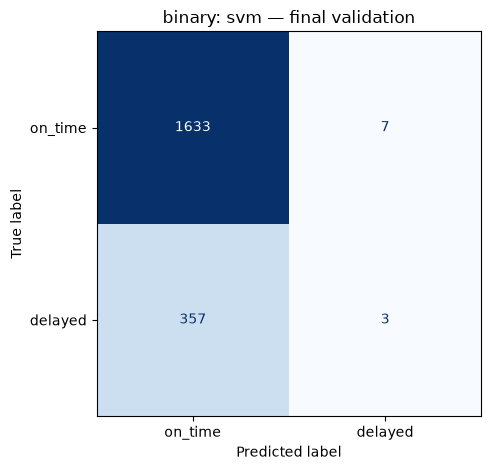

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Validation accuracy:          0.7790
Validation balanced accuracy: 0.3477
Validation macro F1:          0.3437
Final training runtime:       0.2451 seconds
Prediction runtime:           0.0048 seconds


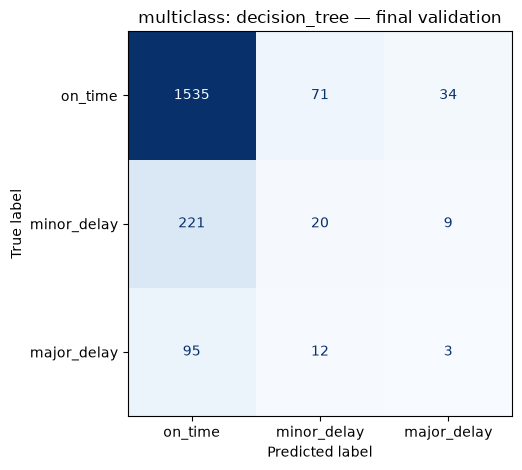

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Validation accuracy:          0.8195
Validation balanced accuracy: 0.3365
Validation macro F1:          0.3081
Final training runtime:       15.2212 seconds
Prediction runtime:           0.3714 seconds


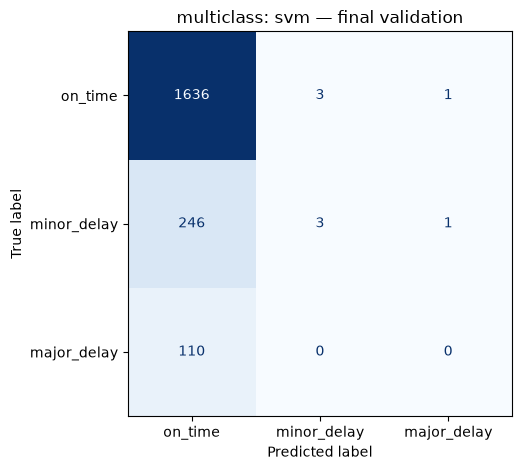

,classification,model,best_parameters,cv_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,training_seconds,prediction_seconds
0,binary,decision_tree,{'model__max_depth': 20},0.519601,0.7910,0.524593,0.518983,0.229993,0.005305
1,binary,svm,{'model__kernel': 'poly'},0.460428,0.8180,0.502033,0.457970,13.851824,0.307934
2,multiclass,decision_tree,{'model__max_depth': 20},0.337846,0.7790,0.347749,0.343727,0.245054,0.004786
3,multiclass,svm,{'model__kernel': 'poly'},0.305143,0.8195,0.336520,0.308106,15.221175,0.371388


In [25]:
results = []
best_models = {}
cv_tables = {}

for classification, split in splits.items():
    X_train, y_train, X_validation, y_validation = split

    folds = list(StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, y_train))

    for model in models:
        model_estimator, hyperparameters = model_specs[model]
        pipeline = make_pipeline(model_estimator)

        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=hyperparameters,
            scoring="f1_macro",
            cv=folds,
            n_jobs=-1,
            verbose=1,
            refit=False,
        )

        grid_search.fit(X_train, y_train)

        cv_table = pd.DataFrame(grid_search.cv_results_)
        cv_tables[(classification, model)] = cv_table

        mean_test_scores = cv_table[["mean_test_score", "std_test_score"]].copy()

        best_index = mean_test_scores["mean_test_score"].idxmax()
        best_params = grid_search.cv_results_["params"][best_index]

        best_model = make_pipeline(model_estimator).set_params(**best_params)
        
        start_time = perf_counter()
        best_model.fit(X_train, y_train)
        fit_time = perf_counter() - start_time

        start_time = perf_counter()
        predictions = best_model.predict(X_validation)
        prediction_seconds = perf_counter() - start_time

        best_models[(classification, model)] = best_model
        accuracy = accuracy_score(y_validation, predictions)
        balanced_accuracy = balanced_accuracy_score(y_validation, predictions)
        macro_f1 = f1_score(y_validation, predictions, average="macro")

        labels = np.arange(len(class_names[classification]))

        print(f"Validation accuracy:          {accuracy:.4f}")
        print(f"Validation balanced accuracy: {balanced_accuracy:.4f}")
        print(f"Validation macro F1:          {macro_f1:.4f}")
        print(f"Final training runtime:       {fit_time:.4f} seconds")
        print(f"Prediction runtime:           {prediction_seconds:.4f} seconds")

        ConfusionMatrixDisplay.from_predictions(
            y_validation,
            predictions,
            labels=labels,
            display_labels=class_names[classification],
            cmap="Blues",
            colorbar=False,
        )

        plt.title(f"{classification}: {model} — final validation")
        plt.tight_layout()
        plt.show()

        results.append({
            "classification": classification,
            "model": model,
            "best_parameters": str(best_params),
            "cv_macro_f1": mean_test_scores.loc[best_index, "mean_test_score"],
            "validation_accuracy": accuracy,
            "validation_balanced_accuracy": balanced_accuracy,
            "validation_macro_f1": macro_f1,
            "training_seconds": fit_time,
            "prediction_seconds": prediction_seconds,
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["classification", "validation_macro_f1"], ascending=[True, False]))
results_df.to_csv(OUTPUT_DIR / "model_fitting_results.csv", index=False)
for (classification, model), cv_table in cv_tables.items():
    cv_table.to_csv(OUTPUT_DIR / f"cv_results_{classification}_{model}.csv", index=False)  

